# Proyek Akhir Data Science - Analisis dan Prediksi Pembatalan Reservasi Hotel: Pendekatan *Data Science* untuk Mengidentifikasi Faktor Risiko dan Mendukung Strategi *Overbooking*

---
Kelompok - Aliansi Cinta dan Jagung Bakar:

- Vania Christabella		(123240235)
- Jelita Syahwa Nabila		(123240243)
- Mutiara Rahmawati Zalsa	(123240257)
- Aliffa Izza Ferryna   	(123240258)
---


## Business Understanding

## Business Understanding

### Latar Belakang
Pembatalan reservasi merupakan salah satu permasalahan dalam pengelolaan hotel karena dapat memengaruhi ketersediaan kamar dan potensi pendapatan. Ketika tamu membatalkan reservasi, kamar yang sebelumnya telah dipesan berpotensi tidak terjual kembali, terutama apabila pembatalan terjadi mendekati tanggal kedatangan.

Di sisi lain, hotel perlu mengantisipasi kemungkinan pembatalan agar dapat mengelola reservasi secara lebih efektif. Salah satu pendekatan yang dapat digunakan adalah Data Science untuk menganalisis pola pembatalan berdasarkan karakteristik reservasi dan membangun model yang dapat memprediksi kemungkinan pembatalan.

Proyek ini menggunakan Hotel Booking Demand Dataset yang berisi informasi historis reservasi hotel, seperti waktu pemesanan, jenis hotel, segmen pasar, jenis deposit, serta status pembatalan. Melalui analisis data dan pemodelan klasifikasi, proyek ini bertujuan mengidentifikasi pola yang berkaitan dengan pembatalan dan memperkirakan risiko pembatalan reservasi.

### Solusi
Solusi yang diusulkan adalah menerapkan pendekatan Data Science melalui analisis eksplorasi data (*Exploratory Data Analysis* atau EDA) dan pemodelan klasifikasi (*supervised learning*). EDA digunakan untuk memahami distribusi pembatalan serta hubungan antara karakteristik reservasi dan status pembatalan. Selanjutnya, model klasifikasi digunakan untuk memprediksi apakah suatu reservasi berpotensi dibatalkan (kelas 1) atau tidak (kelas 0) berdasarkan informasi yang sudah tersedia **saat reservasi dibuat**.

Hasil analisis dan prediksi diharapkan menjadi bahan pertimbangan bagi pengelola hotel dalam mengidentifikasi reservasi berisiko, meningkatkan strategi pengelolaan kamar, dan mempertimbangkan kebijakan *overbooking* secara lebih terukur. Namun, keputusan *overbooking* tetap perlu mempertimbangkan kapasitas kamar, potensi kerugian, serta risiko ketika tamu yang telah memesan ternyata tetap datang.


## Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## Memuat Dataset

In [3]:
df_raw = pd.read_csv("Dataset/hotel_bookings.csv")
print("Ukuran dataset asli (baris, kolom):", df_raw.shape)
df_raw.head()

Ukuran dataset asli (baris, kolom): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
# Melihat jumlah baris dan kolom serta jenis data dalam dataset
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
# Melihat statistik deskriptif dataset
df_raw.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


## Random Sampling

In [6]:
# Mengambil sampel acak 50.000 baris tanpa pengembalian (sesuai masukan aslab: 10.000 - 100.000 data)
df = df_raw.sample(n=50_000, random_state=42, replace=False).reset_index(drop=True)

print("Ukuran dataset asli  :", df_raw.shape)
print("Ukuran dataset sampel:", df.shape)

Ukuran dataset asli  : (119390, 32)
Ukuran dataset sampel: (50000, 32)


In [7]:
# Membandingkan proporsi target pada dataset asli dan sampel
target_comparison = pd.DataFrame({
    "Dataset Asli (%)": df_raw["is_canceled"].value_counts(normalize=True).sort_index() * 100,
    "Dataset Sampel (%)": df["is_canceled"].value_counts(normalize=True).sort_index() * 100,
})
target_comparison.index.name = "is_canceled"
target_comparison.round(2)

,Dataset Asli (%),Dataset Sampel (%)
is_canceled,,
0,62.96,62.84
1,37.04,37.16


## Data Understanding

In [8]:
# Membuat copy dataset untuk EDA
df_eda = df.copy()
df_eda.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,203,2016,December,49,2,2,5,2,0.0,0,BB,GBR,Direct,Direct,0,0,0,F,F,4,No Deposit,250.0,NaN,0,Transient,66.8,0,0,Check-Out,2016-12-09
1,City Hotel,1,82,2015,July,29,16,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,76.5,0,0,Canceled,2015-07-16
2,City Hotel,0,25,2016,December,53,27,0,3,3,0.0,0,BB,BRA,Offline TA/TO,TA/TO,0,0,0,A,K,2,No Deposit,220.0,NaN,0,Transient-Party,60.0,0,1,Check-Out,2016-12-30
3,City Hotel,0,1,2016,March,11,9,0,1,1,0.0,0,BB,SWE,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient-Party,95.0,0,0,Check-Out,2016-03-10
4,City Hotel,0,70,2017,April,16,16,2,2,2,0.0,0,SC,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,108.0,0,0,Check-Out,2017-04-20


In [9]:
# Menghitung jumlah missing value dan presentasenya
missing_data = df_eda.isnull().sum().reset_index()
missing_data.columns = ["Kolom", "Jumlah Missing Value"]
missing_data["Persentase Missing Value(%)"] = missing_data["Jumlah Missing Value"] / len(df_eda) * 100
missing_data = missing_data[missing_data["Jumlah Missing Value"] > 0].sort_values("Jumlah Missing Value", ascending=False)
display(missing_data)

,Kolom,Jumlah Missing Value,Persentase Missing Value(%)
24,company,47155,94.310
23,agent,6842,13.684
13,country,209,0.418


In [10]:
# Mengecek baris yang duplikat
duplicate_rows = df_eda.duplicated().sum()
print(f"Jumlah baris duplicate: {duplicate_rows} ({duplicate_rows / len(df_eda) * 100:.2f}%)")

Jumlah baris duplicate: 10735 (21.47%)


In [11]:
# Mengecek jumlah reservasi yang dibatalkan
print(df_eda["is_canceled"].value_counts())
print(f"Persentase dibatalkan: {df_eda['is_canceled'].mean() * 100:.2f}%")

is_canceled
0    31420
1    18580
Name: count, dtype: int64
Persentase dibatalkan: 37.16%


In [12]:
# Mengecek nilai yang tidak wajar
total_nights = df_eda["stays_in_weekend_nights"] + df_eda["stays_in_week_nights"]
total_guests = df_eda["adults"] + df_eda["children"].fillna(0) + df_eda["babies"]

print(f"Reservasi tanpa tamu (adults + children + babies = 0): {(total_guests == 0).sum()}")
print(f"Reservasi dengan adults > 10                         : {(df_eda['adults'] > 10).sum()}")
print(f"Reservasi dengan ADR < 0                             : {(df_eda['adr'] < 0).sum()}")
print(f"Reservasi dengan ADR = 0                             : {(df_eda['adr'] == 0).sum()}")
print(f"Reservasi dengan lama menginap = 0 malam             : {(total_nights == 0).sum()}")
print(f"Reservasi dengan lama menginap > 30 malam            : {(total_nights > 30).sum()}")

Reservasi tanpa tamu (adults + children + babies = 0): 69
Reservasi dengan adults > 10                         : 2
Reservasi dengan ADR < 0                             : 1
Reservasi dengan ADR = 0                             : 780
Reservasi dengan lama menginap = 0 malam             : 298
Reservasi dengan lama menginap > 30 malam            : 8


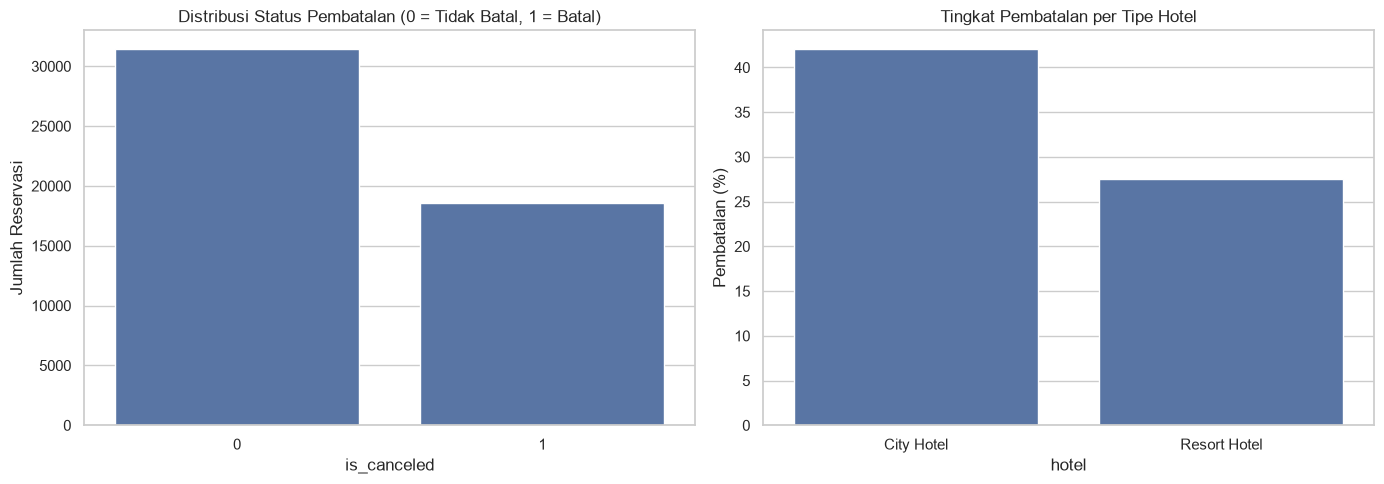

In [13]:
# Visualisasi distribusi pembatalan dan tingkat pembatalan per tipe hotel
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_eda, x="is_canceled", ax=ax[0])
ax[0].set_title("Distribusi Status Pembatalan (0 = Tidak Batal, 1 = Batal)")
ax[0].set_xlabel("is_canceled")
ax[0].set_ylabel("Jumlah Reservasi")

hotel_rate = df_eda.groupby("hotel")["is_canceled"].mean() * 100
sns.barplot(x=hotel_rate.index, y=hotel_rate.values, ax=ax[1])
ax[1].set_title("Tingkat Pembatalan per Tipe Hotel")
ax[1].set_ylabel("Pembatalan (%)")

plt.tight_layout()
plt.show()

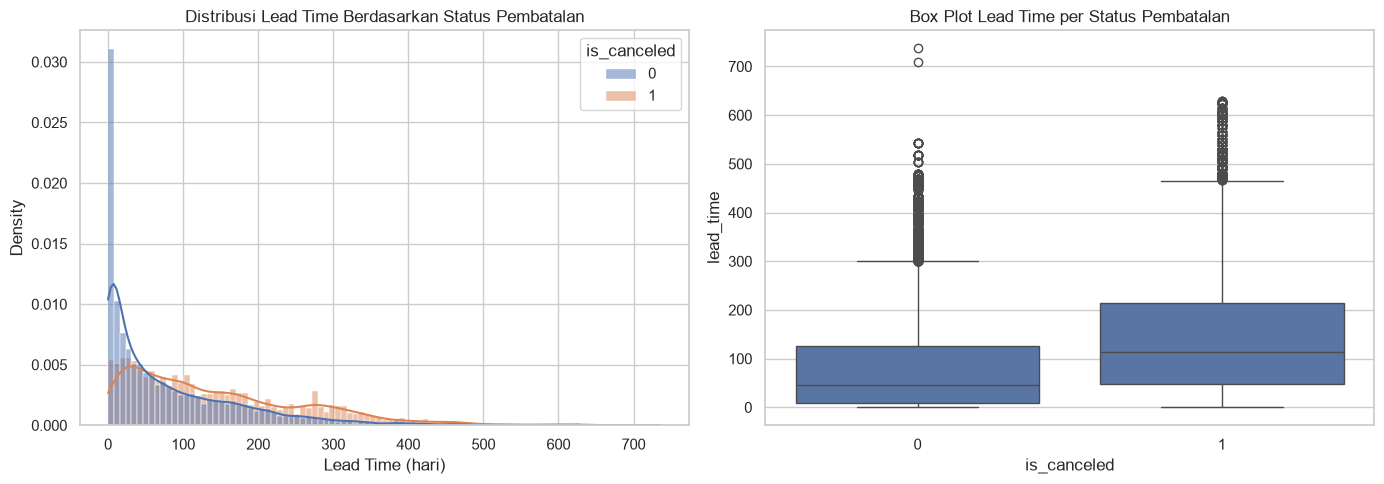

In [14]:
# Visualisasi lead time berdasarkan status pembatalan (histogram dan box plot)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_eda, x="lead_time", hue="is_canceled", kde=True, stat="density", common_norm=False, ax=ax[0])
ax[0].set_title("Distribusi Lead Time Berdasarkan Status Pembatalan")
ax[0].set_xlabel("Lead Time (hari)")

sns.boxplot(data=df_eda, x="is_canceled", y="lead_time", ax=ax[1])
ax[1].set_title("Box Plot Lead Time per Status Pembatalan")

plt.tight_layout()
plt.show()

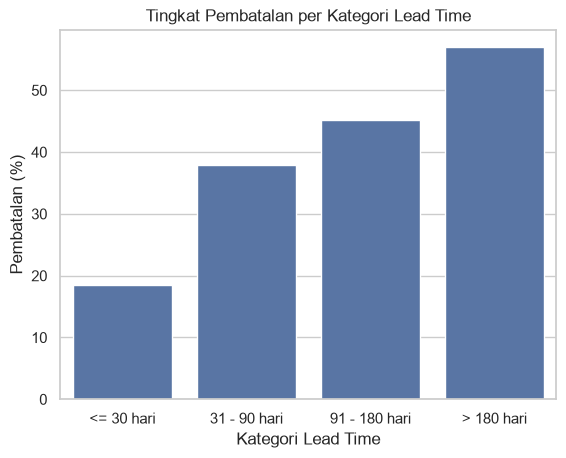

In [15]:
# Binning lead time menjadi kategori, lalu melihat tingkat pembatalan tiap kategori
bins = [-1, 30, 90, 180, df_eda["lead_time"].max()]
labels = ["<= 30 hari", "31 - 90 hari", "91 - 180 hari", "> 180 hari"]
df_eda["lead_time_category"] = pd.cut(df_eda["lead_time"], bins=bins, labels=labels)

lead_rate = df_eda.groupby("lead_time_category", observed=True)["is_canceled"].mean() * 100
sns.barplot(x=lead_rate.index, y=lead_rate.values)
plt.title("Tingkat Pembatalan per Kategori Lead Time")
plt.xlabel("Kategori Lead Time")
plt.ylabel("Pembatalan (%)")
plt.show()

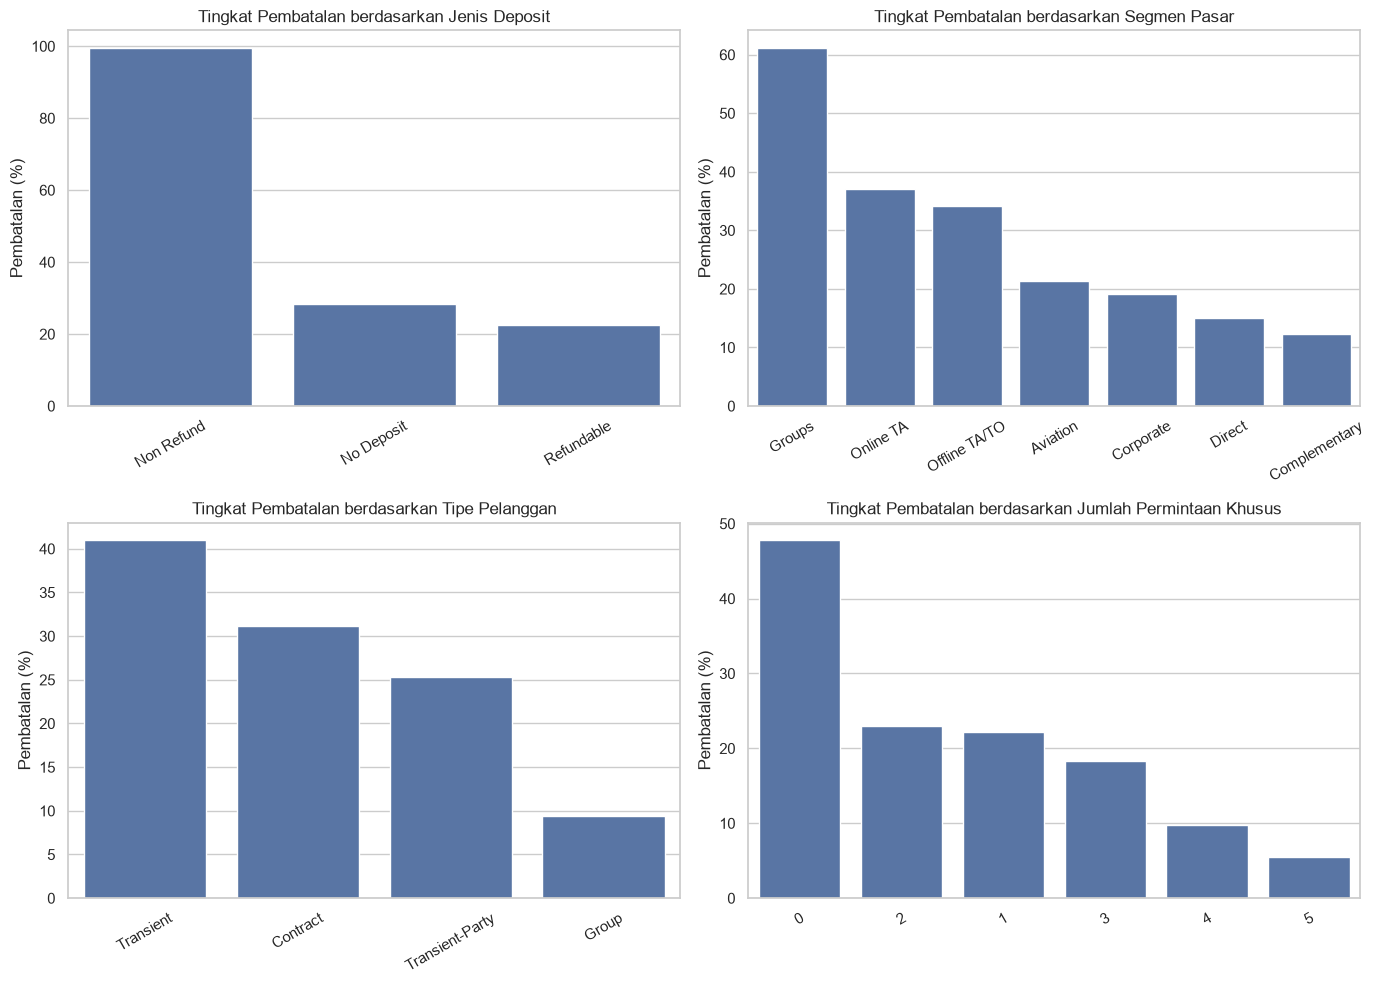

In [16]:
# Visualisasi tingkat pembatalan berdasarkan deposit, segmen pasar, tipe pelanggan, dan permintaan khusus
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

for axis, col, title in zip(
    ax.ravel(),
    ["deposit_type", "market_segment", "customer_type", "total_of_special_requests"],
    ["Jenis Deposit", "Segmen Pasar", "Tipe Pelanggan", "Jumlah Permintaan Khusus"],
):
    rate = (df_eda.groupby(col)["is_canceled"].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axis)
    axis.set_title(f"Tingkat Pembatalan berdasarkan {title}")
    axis.set_xlabel("")
    axis.set_ylabel("Pembatalan (%)")
    axis.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

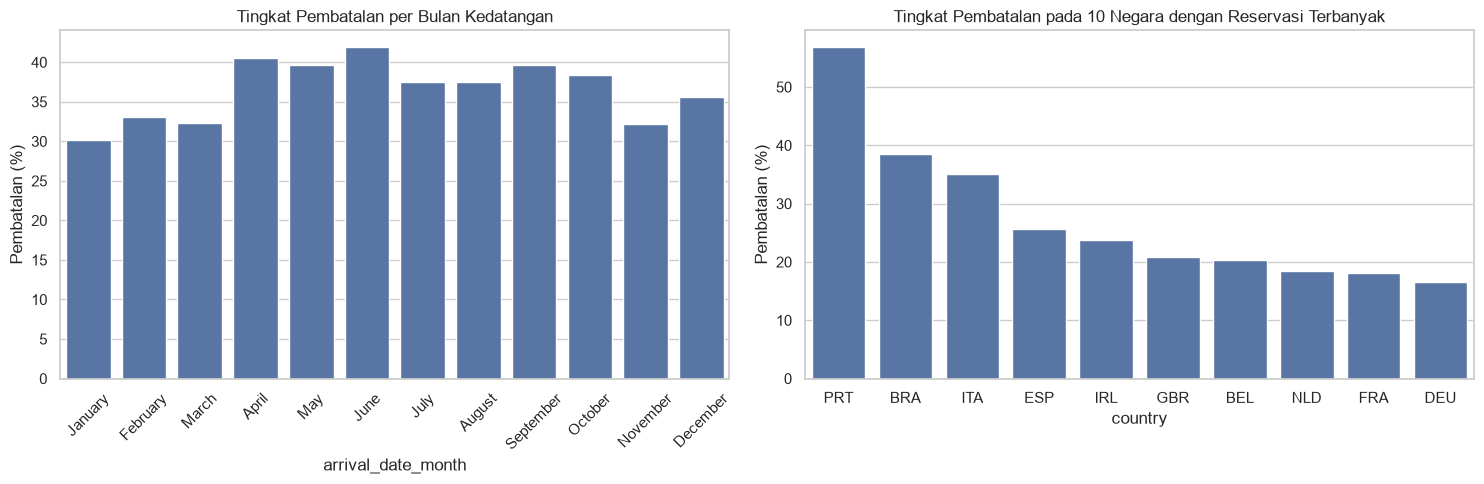

In [17]:
# Visualisasi tingkat pembatalan per bulan kedatangan dan per negara (10 negara terbanyak)
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

month_rate = df_eda.groupby("arrival_date_month")["is_canceled"].mean().reindex(month_order) * 100
sns.barplot(x=month_rate.index, y=month_rate.values, ax=ax[0])
ax[0].set_title("Tingkat Pembatalan per Bulan Kedatangan")
ax[0].set_ylabel("Pembatalan (%)")
ax[0].tick_params(axis="x", rotation=45)

top_countries = df_eda["country"].value_counts().head(10).index
country_rate = df_eda[df_eda["country"].isin(top_countries)].groupby("country")["is_canceled"].mean() * 100
country_rate = country_rate.sort_values(ascending=False)
sns.barplot(x=country_rate.index, y=country_rate.values, ax=ax[1])
ax[1].set_title("Tingkat Pembatalan pada 10 Negara dengan Reservasi Terbanyak")
ax[1].set_ylabel("Pembatalan (%)")

plt.tight_layout()
plt.show()

## Data Preparation

In [18]:
# Membuat copy dataset untuk Data Preparation
df_clean = df_eda.drop(columns=["lead_time_category"]).copy()
print("Ukuran dataset sebelum preparation:", df_clean.shape)

Ukuran dataset sebelum preparation: (50000, 32)


In [19]:
# Menghapus baris yang duplikat
rows_before = len(df_clean)
cancel_before = df_clean["is_canceled"].mean() * 100

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

rows_after = len(df_clean)
cancel_after = df_clean["is_canceled"].mean() * 100

print(f"Jumlah baris sebelum dihapus : {rows_before}")
print(f"Jumlah baris setelah dihapus : {rows_after}")
print(f"Total baris yang dihapus     : {rows_before - rows_after}")
print(f"Proporsi pembatalan sebelum  : {cancel_before:.2f}%")
print(f"Proporsi pembatalan sesudah  : {cancel_after:.2f}%")

Jumlah baris sebelum dihapus : 50000
Jumlah baris setelah dihapus : 39265
Total baris yang dihapus     : 10735
Proporsi pembatalan sebelum  : 37.16%
Proporsi pembatalan sesudah  : 28.69%


In [20]:
# Menghapus kolom company karena missing value sangat tinggi (> 90%)
df_clean = df_clean.drop(columns=["company"])
print("Ukuran dataset:", df_clean.shape)

Ukuran dataset: (39265, 31)


In [21]:
# Menangani missing value dengan imputasi nilai tunggal
df_clean["children"] = df_clean["children"].fillna(0).astype(int)   # tidak ada info anak dianggap 0
df_clean["country"] = df_clean["country"].fillna("Unknown")         # negara tidak diketahui
df_clean["agent"] = df_clean["agent"].fillna(0).astype(int)         # agent adalah ID, 0 = reservasi tanpa agent

print("Sisa missing value:", df_clean.isnull().sum().sum())

Sisa missing value: 0


In [22]:
# Menghapus baris dengan nilai tidak wajar
rows_before = len(df_clean)

total_nights = df_clean["stays_in_weekend_nights"] + df_clean["stays_in_week_nights"]
total_guests = df_clean["adults"] + df_clean["children"] + df_clean["babies"]

invalid = (total_guests == 0) | (df_clean["adults"] > 10) | (df_clean["adr"] < 0) | (total_nights == 0)
df_clean = df_clean[~invalid].reset_index(drop=True)

rows_after = len(df_clean)
print(f"Jumlah baris sebelum dihapus : {rows_before}")
print(f"Jumlah baris setelah dihapus : {rows_after}")
print(f"Total baris yang dihapus     : {rows_before - rows_after}")
print("Catatan: ADR = 0 dan lama menginap > 30 malam dipertahankan karena masih dapat berupa reservasi sah (mis. kamar komplimenter).")

Jumlah baris sebelum dihapus : 39265
Jumlah baris setelah dihapus : 38941
Total baris yang dihapus     : 324
Catatan: ADR = 0 dan lama menginap > 30 malam dipertahankan karena masih dapat berupa reservasi sah (mis. kamar komplimenter).


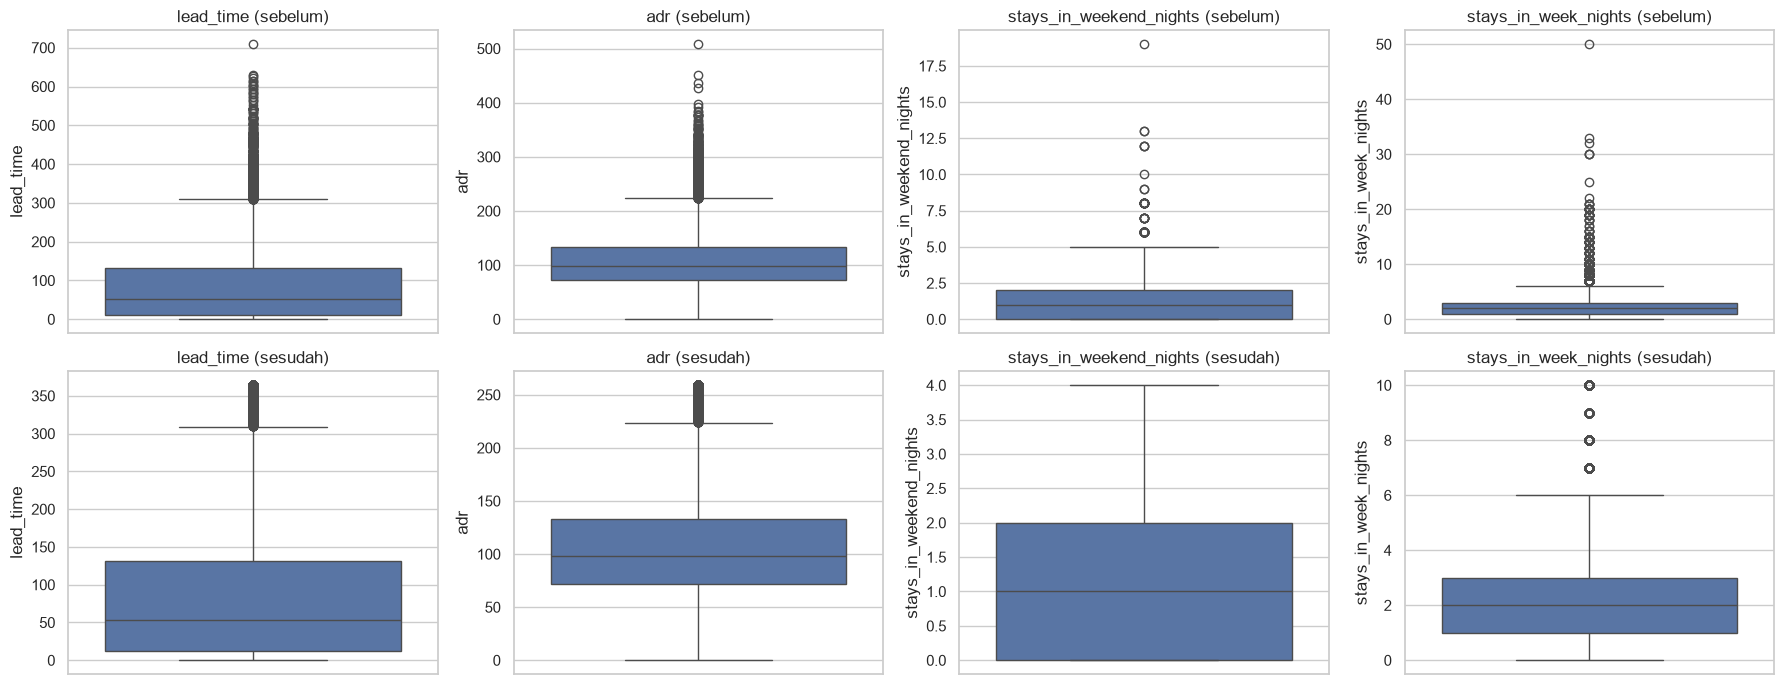

Batas atas capping: {'lead_time': np.float64(364.0), 'adr': np.float64(259.0), 'stays_in_weekend_nights': np.float64(4.0), 'stays_in_week_nights': np.float64(10.0)}


In [23]:
# Menangani outlier dengan capping (batas atas persentil ke-99), lalu membandingkan boxplot sebelum dan sesudah
cols_outlier = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights"]

fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(cols_outlier):
    sns.boxplot(y=df_clean[col], ax=ax[0, i])
    ax[0, i].set_title(f"{col} (sebelum)")

capping_limits = {}
for col in cols_outlier:
    upper_limit = df_clean[col].quantile(0.99)
    df_clean[col] = df_clean[col].clip(upper=upper_limit)
    capping_limits[col] = upper_limit

for i, col in enumerate(cols_outlier):
    sns.boxplot(y=df_clean[col], ax=ax[1, i])
    ax[1, i].set_title(f"{col} (sesudah)")

plt.tight_layout()
plt.show()
print("Batas atas capping:", capping_limits)

In [24]:
# Validasi tipe data setelah pembersihan
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 38941 entries, 0 to 38940
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           38941 non-null  str    
 1   is_canceled                     38941 non-null  int64  
 2   lead_time                       38941 non-null  int64  
 3   arrival_date_year               38941 non-null  int64  
 4   arrival_date_month              38941 non-null  str    
 5   arrival_date_week_number        38941 non-null  int64  
 6   arrival_date_day_of_month       38941 non-null  int64  
 7   stays_in_weekend_nights         38941 non-null  int64  
 8   stays_in_week_nights            38941 non-null  int64  
 9   adults                          38941 non-null  int64  
 10  children                        38941 non-null  int64  
 11  babies                          38941 non-null  int64  
 12  meal                            38941 non-n

## Feature Selection (Menghindari Data Leakage)

Model hanya boleh memakai informasi yang sudah diketahui **saat reservasi dibuat**. Memakai informasi yang baru diketahui setelah kejadian akan membuat skor model terlihat sangat tinggi, tetapi gagal saat dipakai di kondisi nyata (*data leakage*). Kolom berikut dibuang:
- `reservation_status` dan `reservation_status_date`: berisi hasil akhir reservasi (Canceled / Check-Out / No-Show) sehingga membocorkan target.
- `assigned_room_type`: tipe kamar yang benar-benar diberikan, baru diketahui saat tamu tiba.
- `arrival_date_year`, `arrival_date_week_number`, `arrival_date_day_of_month`: pola waktu sudah diwakili `arrival_date_month`, dan tahun tidak bisa digeneralisasi ke masa depan.

In [25]:
# Membuang kolom yang menyebabkan data leakage dan kolom yang tidak diperlukan
drop_cols = [
    "reservation_status", "reservation_status_date", "assigned_room_type",
    "arrival_date_year", "arrival_date_week_number", "arrival_date_day_of_month",
]
df_clean = df_clean.drop(columns=drop_cols)

print("Ukuran dataset setelah feature selection:", df_clean.shape)
print("Jumlah missing value:", df_clean.isnull().sum().sum())

Ukuran dataset setelah feature selection: (38941, 25)
Jumlah missing value: 0


In [26]:
# Ekspor data yang sudah dibersihkan
df_clean.to_csv("hotel_bookings_clean.csv", index=False)

In [27]:
# Tingkat pembatalan (%) pada data bersih untuk beberapa faktor utama
df_summary = df_clean.copy()
df_summary["lead_time_category"] = pd.cut(df_summary["lead_time"], bins=[-1, 30, 90, 180, df_summary["lead_time"].max()],
                                          labels=["<= 30 hari", "31 - 90 hari", "91 - 180 hari", "> 180 hari"])

for col in ["hotel", "deposit_type", "market_segment", "customer_type", "total_of_special_requests", "lead_time_category"]:
    rate = (df_summary.groupby(col, observed=True)["is_canceled"].mean() * 100).round(1)
    print(f"--- {col}")
    print(rate.to_string(), "\n")

print("--- required_car_parking_spaces")
print("Pembatalan pada reservasi yang meminta parkir (%):", round(df_summary[df_summary["required_car_parking_spaces"] > 0]["is_canceled"].mean() * 100, 1))
print("Baris yang identik pada seluruh fitur yang dipakai:", df_clean.duplicated().sum())

--- hotel
hotel
City Hotel      31.7
Resort Hotel    24.2 

--- deposit_type
deposit_type
No Deposit    27.4
Non Refund    96.7
Refundable    24.3 

--- market_segment
market_segment
Aviation         21.5
Complementary    11.7
Corporate        13.1
Direct           14.9
Groups           34.1
Offline TA/TO    17.1
Online TA        36.4 

--- customer_type
customer_type
Contract           18.4
Group               8.6
Transient          31.7
Transient-Party    17.4 

--- total_of_special_requests
total_of_special_requests
0    35.1
1    22.8
2    22.7
3    17.6
4    10.1
5     5.6 

--- lead_time_category
lead_time_category
<= 30 hari       17.0
31 - 90 hari     32.7
91 - 180 hari    36.2
> 180 hari       42.6 

--- required_car_parking_spaces
Pembatalan pada reservasi yang meminta parkir (%): 0.0
Baris yang identik pada seluruh fitur yang dipakai: 661


## Feature Engineering

In [28]:
# Membuat salinan untuk feature engineering
df_fe = df_clean.copy()

# Feature creation: menggabungkan beberapa kolom menjadi fitur yang lebih informatif
df_fe["total_nights"] = df_fe["stays_in_weekend_nights"] + df_fe["stays_in_week_nights"]
df_fe["total_guests"] = df_fe["adults"] + df_fe["children"] + df_fe["babies"]
df_fe["has_children"] = ((df_fe["children"] + df_fe["babies"]) > 0).astype(int)   # binary feature

df_fe[["total_nights", "total_guests", "has_children"]].head()

,total_nights,total_guests,has_children
0,7,2,0
1,3,2,0
2,3,3,0
3,1,1,0
4,4,2,0


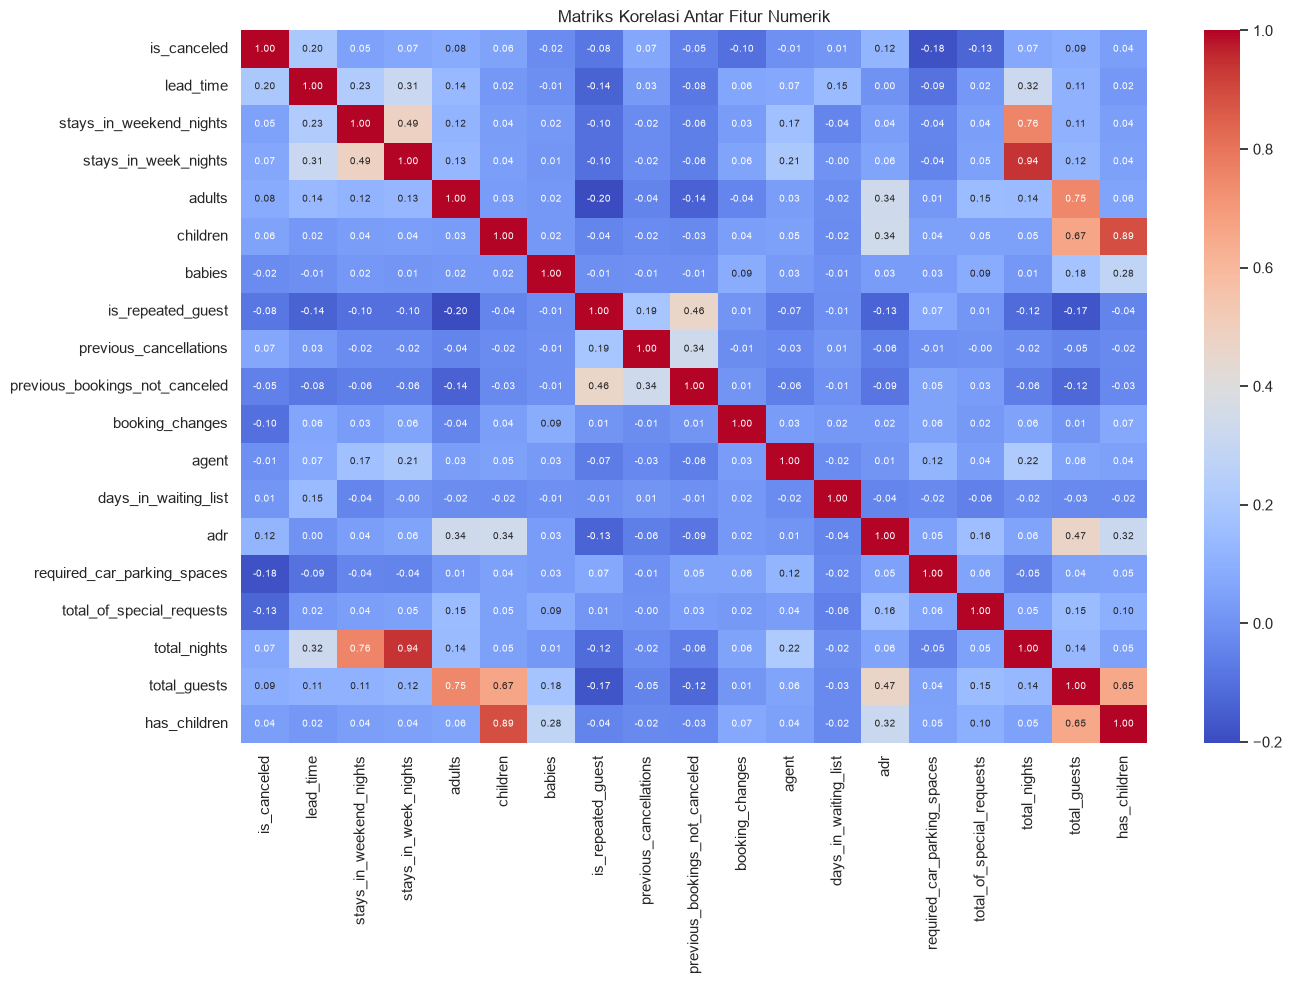

In [29]:
# Visualisasi korelasi antar fitur numerik
num_corr = df_fe.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Matriks Korelasi Antar Fitur Numerik")
plt.tight_layout()
plt.show()

In [31]:
# Label encoding untuk hotel (hanya dua kategori)
label_encoder = LabelEncoder()
df_fe["hotel"] = label_encoder.fit_transform(df_fe["hotel"])
print("Kelas hotel:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Kelas hotel: {np.int64(0): np.int64(0), np.int64(1): np.int64(1)}


In [32]:
# Ordinal encoding untuk bulan kedatangan berdasarkan urutan kalender
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
df_fe["arrival_date_month"] = df_fe["arrival_date_month"].map({m: i + 1 for i, m in enumerate(month_order)})
df_fe[["arrival_date_month"]].head()

,arrival_date_month
0,12
1,7
2,12
3,3
4,4


In [33]:
# Frequency encoding untuk country dan agent (kategori terlalu banyak jika di-one-hot)
for col in ["country", "agent"]:
    df_fe[col + "_freq"] = df_fe[col].map(df_fe[col].value_counts(normalize=True))
df_fe = df_fe.drop(columns=["country", "agent"])

df_fe[["country_freq", "agent_freq"]].head()

,country_freq,agent_freq
0,0.119514,0.031484
1,0.318764,0.321974
2,0.022881,0.000822
3,0.009502,0.321974
4,0.119514,0.321974


In [34]:
# One-hot encoding untuk kolom kategorikal nominal
ohe_cols = ["meal", "market_segment", "distribution_channel", "reserved_room_type", "deposit_type", "customer_type"]
df_fe = pd.get_dummies(df_fe, columns=ohe_cols, dtype=int)

print("Ukuran dataset setelah encoding:", df_fe.shape)
print("Kolom non-numerik tersisa:", list(df_fe.select_dtypes(exclude=np.number).columns))

Ukuran dataset setelah encoding: (38941, 55)
Kolom non-numerik tersisa: []


## Modelling

### Splitting Dataset

In [35]:
# Mendefinisikan target dan memisahkan fitur
target = "is_canceled"
X = df_fe.drop(columns=target)
y = df_fe[target]

print("Ukuran fitur :", X.shape)
print("Ukuran target:", y.shape)

Ukuran fitur : (38941, 54)
Ukuran target: (38941,)


In [36]:
# Membagi data latih dan data uji (80:20) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)
print("Proporsi pembatalan data latih:", round(y_train.mean() * 100, 2), "%")
print("Proporsi pembatalan data uji  :", round(y_test.mean() * 100, 2), "%")

(31152, 54) (7789, 54)
(31152,) (7789,)
Proporsi pembatalan data latih: 28.87 %
Proporsi pembatalan data uji  : 28.87 %


### Pemilihan Fitur 
Pemilihan fitur memakai metode *filter* berbasis korelasi (seperti pada praktikum): fitur dengan korelasi absolut terhadap target di bawah 0,05 dibuang. Korelasi dihitung hanya pada **data latih** agar data uji tidak ikut memengaruhi pemilihan fitur.

In [37]:
# Menghitung korelasi tiap fitur dengan target pada data latih
train = X_train.copy()
train[target] = y_train

korelasi = train.corr()[target].drop(target).abs().sort_values(ascending=False)
print(korelasi.head(15))

deposit_type_Non Refund          0.223777
deposit_type_No Deposit          0.218651
lead_time                        0.202370
market_segment_Online TA         0.190450
agent_freq                       0.188680
required_car_parking_spaces      0.182142
distribution_channel_TA/TO       0.154703
country_freq                     0.133726
total_of_special_requests        0.129825
distribution_channel_Direct      0.123612
customer_type_Transient          0.123486
adr                              0.121437
market_segment_Direct            0.119542
market_segment_Offline TA/TO     0.116104
customer_type_Transient-Party    0.105914
Name: is_canceled, dtype: float64


In [38]:
# Memilih fitur dengan korelasi absolut >= 0,05
fitur_terpilih = korelasi[korelasi >= 0.05].index
print("Jumlah fitur terpilih:", len(fitur_terpilih), "dari", X_train.shape[1])
print(list(fitur_terpilih))

X_train_sel = X_train[fitur_terpilih]
X_test_sel = X_test[fitur_terpilih]
print(X_train_sel.shape, X_test_sel.shape)

Jumlah fitur terpilih: 28 dari 54
['deposit_type_Non Refund', 'deposit_type_No Deposit', 'lead_time', 'market_segment_Online TA', 'agent_freq', 'required_car_parking_spaces', 'distribution_channel_TA/TO', 'country_freq', 'total_of_special_requests', 'distribution_channel_Direct', 'customer_type_Transient', 'adr', 'market_segment_Direct', 'market_segment_Offline TA/TO', 'customer_type_Transient-Party', 'booking_changes', 'total_guests', 'adults', 'is_repeated_guest', 'distribution_channel_Corporate', 'hotel', 'market_segment_Corporate', 'previous_cancellations', 'total_nights', 'stays_in_week_nights', 'children', 'meal_SC', 'previous_bookings_not_canceled']
(31152, 28) (7789, 28)


### Scaling Data
SVM sensitif terhadap skala fitur, sehingga dilengkapi `StandardScaler` di dalam `Pipeline` (seperti pada praktikum; scaler hanya di-*fit* pada data latih). Decision Tree dan Random Forest tidak sensitif terhadap skala fitur, sehingga dilatih tanpa scaling.

### Tuning Hyperparameter
Kedalaman pohon (`max_depth`) dipilih secara manual (seperti pada Modul Random Forest). Agar data uji tidak dipakai untuk memilih parameter, data latih dibagi lagi menjadi data latih dan data validasi, lalu `max_depth` dengan F1-Score kelas 1 (dibatalkan) tertinggi pada data validasi yang dipilih.

In [39]:
# Membagi data latih menjadi data latih dan data validasi untuk memilih max_depth
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_sel, y_train, test_size=0.25, random_state=42, stratify=y_train
)

depth_options = [5, 10, 15, 20, None]
tuning_rows = []
for depth in depth_options:
    dt = DecisionTreeClassifier(max_depth=depth, min_samples_split=20, random_state=42).fit(X_tr, y_tr)
    rf = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
    tuning_rows.append({
        "max_depth": str(depth),
        "F1 Decision Tree": classification_report(y_val, dt.predict(X_val), output_dict=True)["1"]["f1-score"],
        "F1 Random Forest": classification_report(y_val, rf.predict(X_val), output_dict=True)["1"]["f1-score"],
    })

df_tuning = pd.DataFrame(tuning_rows).set_index("max_depth").round(4)
display(df_tuning)

best_depth_dt = depth_options[df_tuning["F1 Decision Tree"].values.argmax()]
best_depth_rf = depth_options[df_tuning["F1 Random Forest"].values.argmax()]
print("max_depth terbaik Decision Tree:", best_depth_dt)
print("max_depth terbaik Random Forest:", best_depth_rf)

,F1 Decision Tree,F1 Random Forest
max_depth,,
5,0.6419,0.4468
10,0.6701,0.6385
15,0.6794,0.6904
20,0.6626,0.7040
None,0.6531,0.6917


max_depth terbaik Decision Tree: 15
max_depth terbaik Random Forest: 20


### Pelatihan Model

In [40]:
# Membuat dan melatih tiga model klasifikasi pada seluruh data latih
models = {
    "SVM (Linear)": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear")),
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=best_depth_dt, min_samples_split=20, criterion="gini", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=best_depth_rf, criterion="gini", random_state=42, n_jobs=-1
    ),
}

for name, model in models.items():
    model.fit(X_train_sel, y_train)
    print(f"Model {name} berhasil dilatih")

Model SVM (Linear) berhasil dilatih
Model Decision Tree berhasil dilatih
Model Random Forest berhasil dilatih


### Prediksi

In [41]:
# Memprediksi data uji dan menampilkan contoh hasil prediksi
predictions = {name: model.predict(X_test_sel) for name, model in models.items()}

nama_kelas = {0: "Tidak batal", 1: "Batal"}
hasil = pd.DataFrame({
    "Label sebenarnya": y_test.iloc[:8].map(nama_kelas).values,
    "SVM": pd.Series(predictions["SVM (Linear)"][:8]).map(nama_kelas).values,
    "Decision Tree": pd.Series(predictions["Decision Tree"][:8]).map(nama_kelas).values,
    "Random Forest": pd.Series(predictions["Random Forest"][:8]).map(nama_kelas).values,
})
print(hasil)

  Label sebenarnya          SVM Decision Tree Random Forest
0      Tidak batal  Tidak batal   Tidak batal   Tidak batal
1      Tidak batal  Tidak batal   Tidak batal   Tidak batal
2      Tidak batal  Tidak batal   Tidak batal   Tidak batal
3      Tidak batal  Tidak batal         Batal   Tidak batal
4            Batal  Tidak batal   Tidak batal   Tidak batal
5            Batal        Batal         Batal         Batal
6      Tidak batal  Tidak batal   Tidak batal   Tidak batal
7      Tidak batal  Tidak batal   Tidak batal   Tidak batal


## Evaluation

Confusion matrix - SVM (Linear)
                        Diprediksi tidak batal  Diprediksi batal
Sebenarnya tidak batal                    5111               429
Sebenarnya batal                          1170              1079 

Confusion matrix - Decision Tree
                        Diprediksi tidak batal  Diprediksi batal
Sebenarnya tidak batal                    4965               575
Sebenarnya batal                           867              1382 

Confusion matrix - Random Forest
                        Diprediksi tidak batal  Diprediksi batal
Sebenarnya tidak batal                    5063               477
Sebenarnya batal                           802              1447 



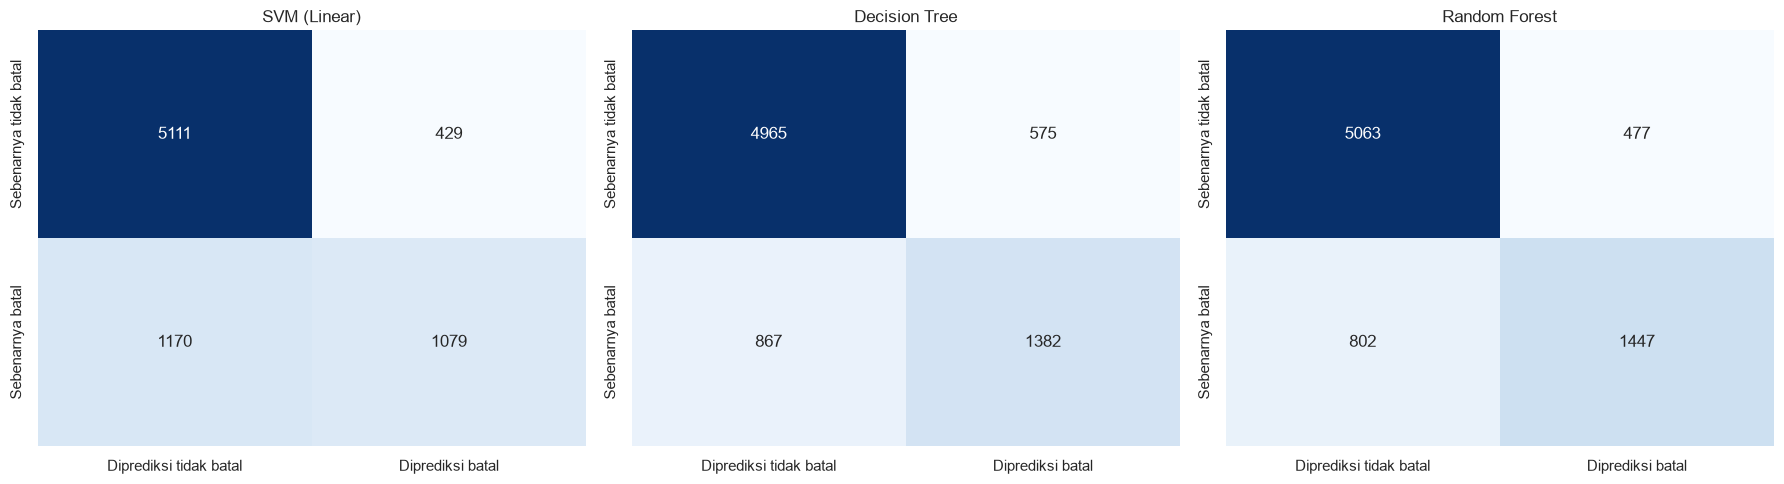

In [42]:
# Confusion matrix tiap model
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for axis, (name, y_pred) in zip(ax, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    cm_df = pd.DataFrame(cm, index=["Sebenarnya tidak batal", "Sebenarnya batal"],
                         columns=["Diprediksi tidak batal", "Diprediksi batal"])
    print(f"Confusion matrix - {name}")
    print(cm_df, "\n")
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", ax=axis, cbar=False)
    axis.set_title(name)

plt.tight_layout()
plt.show()

In [43]:
# Classification report tiap model
for name, y_pred in predictions.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["Tidak batal", "Batal"]))

=== SVM (Linear) ===
              precision    recall  f1-score   support

 Tidak batal       0.81      0.92      0.86      5540
       Batal       0.72      0.48      0.57      2249

    accuracy                           0.79      7789
   macro avg       0.76      0.70      0.72      7789
weighted avg       0.79      0.79      0.78      7789

=== Decision Tree ===
              precision    recall  f1-score   support

 Tidak batal       0.85      0.90      0.87      5540
       Batal       0.71      0.61      0.66      2249

    accuracy                           0.81      7789
   macro avg       0.78      0.76      0.77      7789
weighted avg       0.81      0.81      0.81      7789

=== Random Forest ===
              precision    recall  f1-score   support

 Tidak batal       0.86      0.91      0.89      5540
       Batal       0.75      0.64      0.69      2249

    accuracy                           0.84      7789
   macro avg       0.81      0.78      0.79      7789
weighted 

In [44]:
# Membandingkan performa model pada kelas "Batal" (kelas 1)
rows = []
for name, y_pred in predictions.items():
    rep = classification_report(y_test, y_pred, output_dict=True)
    cm = confusion_matrix(y_test, y_pred)
    rows.append({
        "Model": name,
        "Accuracy": rep["accuracy"],
        "Precision (Batal)": rep["1"]["precision"],
        "Recall (Batal)": rep["1"]["recall"],
        "F1-Score (Batal)": rep["1"]["f1-score"],
        "False Positive": cm[0, 1],
        "False Negative": cm[1, 0],
    })

df_eval = pd.DataFrame(rows).set_index("Model").round(4)
display(df_eval)

best_model_name = df_eval["F1-Score (Batal)"].idxmax()
print("Model terbaik berdasarkan F1-Score kelas Batal:", best_model_name)

,Accuracy,Precision (Batal),Recall (Batal),F1-Score (Batal),False Positive,False Negative
Model,,,,,,
SVM (Linear),0.7947,0.7155,0.4798,0.5744,429,1170
Decision Tree,0.8149,0.7062,0.6145,0.6572,575,867
Random Forest,0.8358,0.7521,0.6434,0.6935,477,802


Model terbaik berdasarkan F1-Score kelas Batal: Random Forest


                        Feature  Importance
2                     lead_time    0.172118
7                  country_freq    0.134199
11                          adr    0.107632
4                    agent_freq    0.099608
8     total_of_special_requests    0.085220
23                 total_nights    0.048540
24         stays_in_week_nights    0.041652
5   required_car_parking_spaces    0.040550
0       deposit_type_Non Refund    0.029737
22       previous_cancellations    0.027753
15              booking_changes    0.025903
1       deposit_type_No Deposit    0.025625
3      market_segment_Online TA    0.025424
10      customer_type_Transient    0.018460
16                 total_guests    0.017215


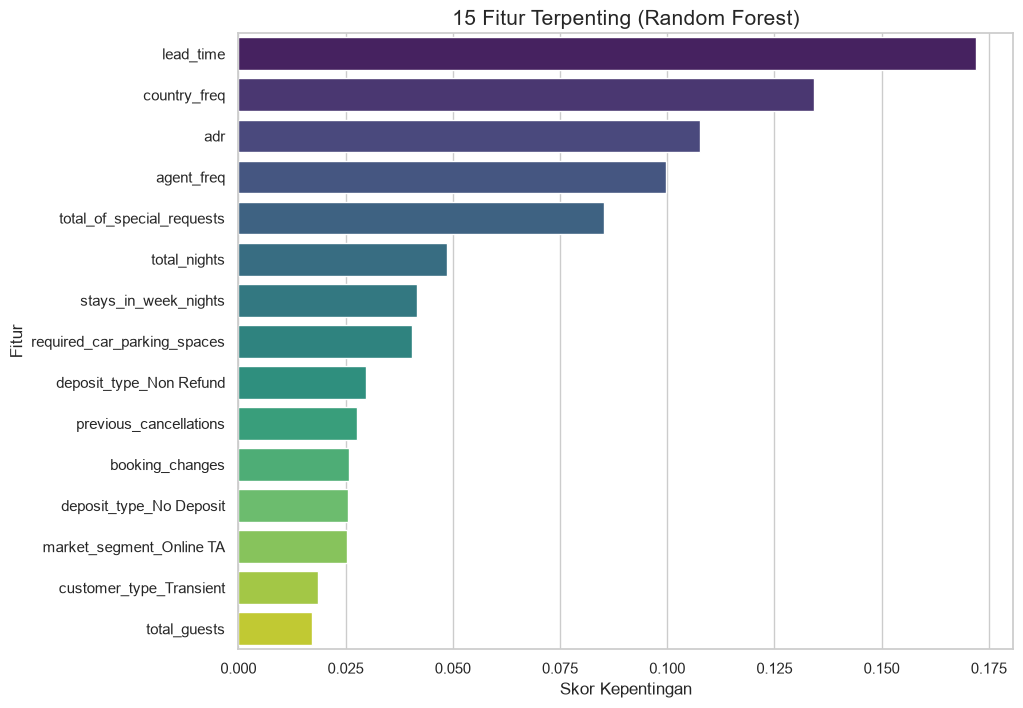

In [45]:
# Analisis feature importance dari Random Forest
rf_model = models["Random Forest"]

feature_importance_df = pd.DataFrame({
    "Feature": X_train_sel.columns,
    "Importance": rf_model.feature_importances_,
}).sort_values(by="Importance", ascending=False)

print(feature_importance_df.head(15))

plt.figure(figsize=(10, 8))
sns.barplot(x="Importance", y="Feature", data=feature_importance_df.head(15), hue="Feature", palette="viridis", legend=False)
plt.title("15 Fitur Terpenting (Random Forest)", fontsize=15)
plt.xlabel("Skor Kepentingan")
plt.ylabel("Fitur")
plt.show()

## Penjelasan Analisis dan Rekomendasi Strategi *Overbooking*

### Ringkasan Hasil
Setelah deduplikasi dan pembersihan, data pemodelan berisi 38.941 reservasi dengan tingkat pembatalan 28,87%. Pemilihan fitur berbasis korelasi mempertahankan 28 dari 54 fitur. Tiga algoritma dibandingkan pada data uji (7.789 reservasi):

| Model | Accuracy | Precision (Batal) | Recall (Batal) | F1-Score (Batal) |
|---|---|---|---|---|
| SVM (Linear) | 0,795 | 0,716 | 0,480 | 0,574 |
| Decision Tree | 0,815 | 0,706 | 0,615 | 0,657 |
| Random Forest | 0,836 | 0,752 | 0,643 | 0,694 |

**Random Forest** (`max_depth=20`, dipilih lewat data validasi) memberikan performa terbaik. SVM dengan kernel linear memiliki *recall* terendah; salah satu penyebab yang mungkin adalah batas keputusan lurus kurang mampu menangkap pola yang tidak linear pada data ini, sedangkan model berbasis pohon lebih fleksibel.

### Faktor Risiko Pembatalan
Berdasarkan ringkasan data bersih dan *feature importance* Random Forest:
- **Lead time**: fitur terpenting. Tingkat pembatalan naik dari 17,0% pada lead time sampai 30 hari menjadi 42,6% pada lead time di atas 180 hari.
- **Permintaan khusus**: reservasi tanpa permintaan khusus dibatalkan 35,1%, sedangkan yang memiliki 4 permintaan khusus hanya 10,1%.
- **Kebutuhan tempat parkir**: tidak ada pembatalan pada reservasi yang meminta tempat parkir.
- **Negara dan agent**: `country_freq` dan `agent_freq` termasuk fitur penting, yang menunjukkan bahwa asal tamu dan agent pemesanan berkaitan dengan risiko pembatalan. Karena keduanya di-*encode* dengan frekuensi, grafik ini tidak menunjukkan negara atau agent mana yang berisiko. Pada grafik EDA, Portugal (PRT) tercatat memiliki tingkat pembatalan tertinggi di antara 10 negara terbanyak.
- **ADR dan lama menginap**: `adr`, `total_nights`, dan `stays_in_week_nights` juga berada di jajaran fitur penting.
- **Segmen pasar**: *Online TA* (36,4%) dan *Groups* (34,1%) lebih berisiko dibanding *Direct* (14,9%) dan *Corporate* (13,1%).
- **Tipe hotel**: *City Hotel* (31,7%) lebih tinggi daripada *Resort Hotel* (24,2%).
- **Jenis deposit**: reservasi *Non Refund* memiliki tingkat pembatalan 96,7%. Pola ini berlawanan dengan logika bisnis (deposit tidak dikembalikan seharusnya menahan pembatalan) dan kemungkinan berkaitan dengan cara pencatatan di dataset ini, sehingga perlu diverifikasi dengan pihak hotel sebelum dijadikan dasar kebijakan.

Seluruh temuan di atas adalah **asosiasi**, bukan bukti sebab-akibat. Skor *feature importance* Random Forest juga cenderung lebih tinggi untuk fitur yang memiliki banyak nilai unik, sehingga urutannya perlu dibaca bersama hasil EDA.

### Kaitan dengan Strategi *Overbooking*
Pada konteks *overbooking*, dua jenis kesalahan prediksi memiliki dampak berbeda:
- ***False Positive*** (diprediksi batal, ternyata tamu datang): inilah risiko *overbooking*, karena hotel mungkin harus menolak atau memindahkan tamu. Pada Random Forest terdapat 477 kasus; dari 1.924 reservasi yang diprediksi batal, sekitar 75% benar-benar batal (*precision* 0,752), sehingga sekitar 25% sisanya tetap datang.
- ***False Negative*** (diprediksi tidak batal, ternyata batal): kamar kosong yang tidak diantisipasi. Pada Random Forest terdapat 802 kasus; model berhasil menangkap 64,3% dari seluruh pembatalan (*recall* 0,643).

Jika hotel lebih takut menolak tamu yang datang, *precision* kelas "Batal" yang menjadi fokus. Jika hotel lebih ingin mengisi kamar yang berpotensi kosong, *recall* yang menjadi fokus. Pilihan yang tepat bergantung pada biaya relokasi tamu dibanding pendapatan kamar kosong, yang tidak tersedia di dataset ini. Hasil model sebaiknya dipakai sebagai pendukung keputusan, misalnya untuk menandai reservasi berisiko tinggi (lead time panjang, tanpa permintaan khusus, segmen *Online TA* atau *Groups*), bukan sebagai pengganti pertimbangan manajer hotel.

### Keterbatasan
- Dataset berasal dari dua hotel di Portugal (2015 - 2017), sehingga belum tentu berlaku untuk hotel lain atau periode lain.
- Dataset tidak memiliki ID reservasi, sehingga baris identik dihapus sebagai duplikat. Proporsi pembatalan turun dari 37,16% menjadi 28,69% karena baris duplikat banyak yang berstatus batal. Baris duplikat juga terkonsentrasi pada kategori tertentu (misalnya *Groups*, *Non Refund*, dan Portugal), sehingga angka pada grafik Data Understanding (sebelum pembersihan) lebih tinggi dibanding angka pada data bersih.
- Setelah kolom tertentu dibuang pada tahap *feature selection*, masih ada sekitar 1,7% baris yang identik pada fitur yang dipakai. Baris ini berasal dari reservasi yang berbeda pada kolom yang dibuang (mis. tanggal kedatangan), sehingga dipertahankan.
- Pemilihan fitur berbasis korelasi hanya menangkap hubungan linear, sehingga fitur yang berpengaruh secara tidak linear bisa ikut terbuang. Tuning hanya mencakup `max_depth`, dan SVM hanya memakai kernel linear seperti pada praktikum.
- Model belum memakai informasi biaya, sehingga hasilnya merupakan dasar awal, bukan keputusan operasional.